# 03. 모델 평가 및 비교

02에서 저장한 두 번째 모델의 테스트 성능과 오예측 기록을 확인한다.
첫 번째 모델도 같은 테스트 데이터에서 평가하여 결과를 비교한다.
첫 번째 모델에서 이미 확인한 테스트 데이터를 다시 사용하므로 재평가 결과로 기록한다.

## 1. 두 번째 모델 불러오기

저장된 모델명, 판단 기준, 측정 항목 수와 테스트 데이터 수를 확인한다.

In [21]:
from pathlib import Path
import joblib

project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

model_path = project_dir / "models" / "defect_prediction.joblib"

# 저장한 모델과 전처리 정보 불러오기
model_bundle = joblib.load(model_path)

print("모델:", model_bundle["model_name"])
print("판단 기준:", model_bundle["threshold"])
print("측정 항목 수:", len(model_bundle["selected_columns"]))
print("테스트 데이터 수:", len(model_bundle["test_indices"]))

모델: Random Forest (두 번째 모델)
판단 기준: 0.3
측정 항목 수: 444
테스트 데이터 수: 314


## 2. 테스트 데이터 불러오기

원본 파일에서 저장된 테스트 행 번호에 해당하는 측정값과 정답을 가져온다.
02 노트북에서 정한 테스트 구성과 행 순서를 유지한다.

In [22]:
import pandas as pd

data_dir = project_dir / "data" / "raw"

# 원본 측정값
X = pd.read_csv(
    data_dir / "secom.data",
    sep=r"\s+",
    header=None
)

# 원본 검사 결과
labels = pd.read_csv(
    data_dir / "secom_labels.data",
    sep=r"\s+",
    header=None,
    names=["result", "timestamp"]
)

y = labels["result"].map({-1: 0, 1: 1})
y.name = "is_defect"

# 02에서 저장한 테스트 행 번호 사용
test_indices = model_bundle["test_indices"]

X_test = X.loc[test_indices].copy()
y_test = y.loc[test_indices].copy()

print("테스트 측정값 크기:", X_test.shape)
print("테스트 정답 개수:", len(y_test))
print("정상 수:", (y_test == 0).sum())
print("불량 수:", (y_test == 1).sum())

테스트 측정값 크기: (314, 590)
테스트 정답 개수: 314
정상 수: 293
불량 수: 21


## 3. 테스트 데이터 전처리

두 번째 모델을 대상으로 확인한다.
저장된 측정 항목을 같은 순서로 선택하고 학습 데이터의 중앙값으로 결측치를 채운다.
표준화 도구가 저장되어 있으면 같은 기준으로 적용한다.

In [24]:
import numpy as np

# 학습 때 선택한 항목과 순서 유지
selected_columns = model_bundle["selected_columns"]
X_test_selected = X_test.loc[:, selected_columns]

# 저장한 중앙값으로 결측치 처리
X_test_processed = model_bundle["imputer"].transform(
    X_test_selected
)

# 표준화가 필요한 모델이면 저장한 도구 적용
saved_scaler = model_bundle["scaler"]

if saved_scaler is not None:
    X_test_processed = saved_scaler.transform(X_test_processed)

print("전처리 후 크기:", X_test_processed.shape)
print("남은 결측치 수:", np.isnan(X_test_processed).sum())

전처리 후 크기: (314, 444)
남은 결측치 수: 0


## 4. 테스트 성능 확인

두 번째 모델을 대상으로 확인한다.
저장한 모델과 판단 기준으로 정상·불량을 예측한다.
정확도와 불량 Precision·Recall·F1을 확인하며, 테스트 결과로 설정을 변경하지 않는다.

In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

saved_model = model_bundle["model"]
saved_threshold = model_bundle["threshold"]

# 클래스 1(불량)에 해당하는 확률 열 확인
defect_column = list(saved_model.classes_).index(1)

test_probabilities = saved_model.predict_proba(
    X_test_processed
)[:, defect_column]

# 저장한 판단 기준으로 정상·불량 구분
test_predictions = (
    test_probabilities >= saved_threshold
).astype(int)

test_metrics = {
    "정확도": accuracy_score(y_test, test_predictions),
    "불량 Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "불량 Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "불량 F1": f1_score(
        y_test, test_predictions, zero_division=0
    )
}

pd.DataFrame(
    [test_metrics],
    index=[model_bundle["model_name"]]
).round(4)

,정확도,불량 Precision,불량 Recall,불량 F1
Random Forest (두 번째 모델),0.9045,0.2857,0.2857,0.2857


## 5. 혼동행렬 확인

두 번째 모델을 대상으로 확인한다.
실제 정상·불량과 예측 결과를 비교해 불량 탐지·놓침과 정상 오탐 건수를 확인한다.

In [26]:
from sklearn.metrics import confusion_matrix

test_cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

pd.DataFrame(
    test_cm,
    index=["실제 정상", "실제 불량"],
    columns=["예측 정상", "예측 불량"]
)

,예측 정상,예측 불량
실제 정상,278,15
실제 불량,15,6


## 6. 놓친 불량 확인

두 번째 모델을 대상으로 확인한다.
실제 불량인데 정상으로 예측한 기록과 불량 예측 확률을 확인한다.
표의 행 번호는 원본 데이터의 행 번호다.

In [27]:
test_results = pd.DataFrame({
    "실제 정답": y_test,
    "예측 결과": test_predictions,
    "불량 예측 확률": test_probabilities
})

missed_defects = test_results[
    (test_results["실제 정답"] == 1)
    & (test_results["예측 결과"] == 0)
]

print("놓친 불량 수:", len(missed_defects))
missed_defects.round(4)

놓친 불량 수: 15


,실제 정답,예측 결과,불량 예측 확률
154,1,0,0.2152
62,1,0,0.1657
1242,1,0,0.2155
576,1,0,0.1340
518,1,0,0.2462
48,1,0,0.2021
336,1,0,0.2765
914,1,0,0.2399
392,1,0,0.2135
231,1,0,0.1773


## 7. 정상 오탐 확인

두 번째 모델을 대상으로 확인한다.
실제 정상인데 불량으로 예측한 기록을 확인한다.
전체 건수를 출력하고 앞의 10건만 표시한다.

In [28]:
false_alarms = test_results[
    (test_results["실제 정답"] == 0)
    & (test_results["예측 결과"] == 1)
]

print("정상 오탐 수:", len(false_alarms))

# 전체 중 앞의 10건만 표시
false_alarms.head(10).round(4)

정상 오탐 수: 15


,실제 정답,예측 결과,불량 예측 확률
245,0,1,0.3069
165,0,1,0.3268
345,0,1,0.3056
268,0,1,0.3409
190,0,1,0.3248
320,0,1,0.3651
233,0,1,0.3284
325,0,1,0.3590
44,0,1,0.3400
215,0,1,0.3219


## 8. 혼동행렬 시각화

두 번째 모델을 대상으로 확인한다.
행은 실제 정답, 열은 예측 결과를 나타낸다.
파란색은 올바른 예측, 붉은색은 잘못된 예측이며 숫자는 기록 수다.
색의 진하기는 건수 크기를 나타내지 않는다.

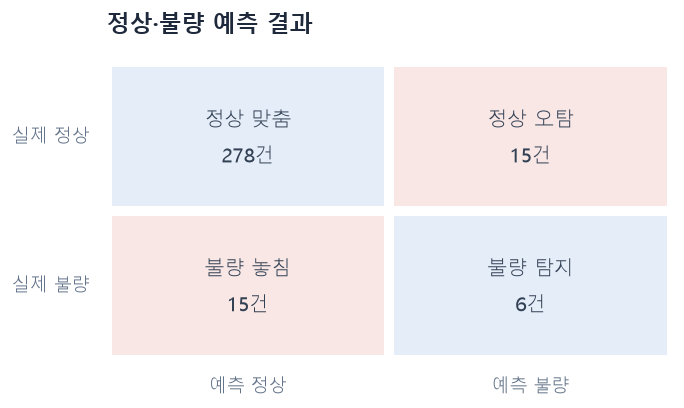

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.colors import ListedColormap

# 맞춘 경우는 파란색, 틀린 경우는 붉은색
cell_colors = np.array([[0, 1], [1, 0]])

cell_labels = np.array([
    [f"정상 맞춤\n{test_cm[0, 0]:,}건",
     f"정상 오탐\n{test_cm[0, 1]:,}건"],
    [f"불량 놓침\n{test_cm[1, 0]:,}건",
     f"불량 탐지\n{test_cm[1, 1]:,}건"]
])

with plt.rc_context({"font.family": "Malgun Gothic"}):
    fig, ax = plt.subplots(figsize=(5.8, 3.5), dpi=120)

    sns.heatmap(
        cell_colors,
        annot=cell_labels,
        fmt="",
        cmap=ListedColormap(["#E5EDF8", "#F8E7E5"]),
        vmin=0,
        vmax=1,
        cbar=False,
        linewidths=5,
        linecolor="white",
        xticklabels=["예측 정상", "예측 불량"],
        yticklabels=["실제 정상", "실제 불량"],
        annot_kws={
            "fontsize": 12,
            "color": "#334155",
            "linespacing": 1.8
        },
        ax=ax
    )

    ax.set_title(
        "정상·불량 예측 결과",
        loc="left",
        fontsize=14,
        fontweight="bold",
        color="#1E293B",
        pad=18
    )

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(
        axis="both",
        length=0,
        labelsize=11,
        labelcolor="#64748B",
        pad=10
    )
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

    plt.tight_layout()
    plt.show()

## 9. 평가 결과 요약

두 번째 모델을 대상으로 확인한다.
실행 결과를 바탕으로 지표와 불량 탐지·놓침, 정상 오탐 건수를 요약한다.

In [30]:
tn, fp, fn, tp = test_cm.ravel()

print("모델:", model_bundle["model_name"])
print("판단 기준:", saved_threshold)
print("테스트 데이터 수:", len(y_test))
print(f"정확도: {test_metrics['정확도']:.2%}")
print(f"불량 Precision: {test_metrics['불량 Precision']:.2%}")
print(f"불량 Recall: {test_metrics['불량 Recall']:.2%}")
print(f"불량 F1: {test_metrics['불량 F1']:.4f}")
print(f"실제 불량 {tp + fn}건 중 {tp}건 탐지, {fn}건 놓침")
print(f"실제 정상 {tn + fp}건 중 {fp}건을 불량으로 오탐")

모델: Random Forest (두 번째 모델)
판단 기준: 0.3
테스트 데이터 수: 314
정확도: 90.45%
불량 Precision: 28.57%
불량 Recall: 28.57%
불량 F1: 0.2857
실제 불량 21건 중 6건 탐지, 15건 놓침
실제 정상 293건 중 15건을 불량으로 오탐


## 10. 첫 번째 모델 평가 및 두 모델 비교

첫 번째 모델의 저장된 전처리와 판단 기준을 적용해 같은 테스트 데이터를 평가한다.
두 모델의 지표와 오예측 건수를 코드로 계산하여 비교한다.
테스트 결과는 비교 기록으로 사용하며 모델이나 판단 기준을 다시 선택하지 않는다.

In [31]:
baseline_path = project_dir / "models" / "defect_prediction_baseline.joblib"
baseline_bundle = joblib.load(baseline_path)

# 두 모델이 동일한 테스트 구성과 순서를 사용하는지 확인
if baseline_bundle["test_indices"] != model_bundle["test_indices"]:
    raise ValueError("두 모델의 테스트 행 번호 또는 순서가 다릅니다.")

# 첫 번째 모델에 저장된 전처리를 별도로 적용
baseline_input = X_test.loc[:, baseline_bundle["selected_columns"]]
baseline_processed = baseline_bundle["imputer"].transform(baseline_input)

if baseline_bundle["scaler"] is not None:
    baseline_processed = baseline_bundle["scaler"].transform(baseline_processed)

baseline_model = baseline_bundle["model"]
baseline_threshold = baseline_bundle["threshold"]
baseline_defect_column = list(baseline_model.classes_).index(1)
baseline_probabilities = baseline_model.predict_proba(
    baseline_processed
)[:, baseline_defect_column]
baseline_predictions = (
    baseline_probabilities >= baseline_threshold
).astype(int)

baseline_cm = confusion_matrix(y_test, baseline_predictions, labels=[0, 1])
baseline_tn, baseline_fp, baseline_fn, baseline_tp = baseline_cm.ravel()

baseline_metrics = {
    "정확도": accuracy_score(y_test, baseline_predictions),
    "불량 Precision": precision_score(y_test, baseline_predictions, zero_division=0),
    "불량 Recall": recall_score(y_test, baseline_predictions, zero_division=0),
    "불량 F1": f1_score(y_test, baseline_predictions, zero_division=0)
}

# 첫 번째와 두 번째 모델의 실제 평가 결과로 비교표 생성
comparison_results = pd.DataFrame([
    {
        "모델": baseline_bundle["model_name"],
        "판단 기준": baseline_threshold,
        **baseline_metrics,
        "불량 탐지": baseline_tp,
        "불량 놓침": baseline_fn,
        "정상 오탐": baseline_fp
    },
    {
        "모델": model_bundle["model_name"],
        "판단 기준": saved_threshold,
        **test_metrics,
        "불량 탐지": tp,
        "불량 놓침": fn,
        "정상 오탐": fp
    }
]).set_index("모델")

comparison_results.round(4)

,판단 기준,정확도,불량 Precision,불량 Recall,불량 F1,불량 탐지,불량 놓침,정상 오탐
모델,,,,,,,,
Random Forest (첫 번째 모델),0.2,0.8471,0.2545,0.6667,0.3684,14,7,41
Random Forest (두 번째 모델),0.3,0.9045,0.2857,0.2857,0.2857,6,15,15


검증에서는 두 번째 모델의 F1이 높았지만, 앞서 확인한 테스트 결과에서는
정상 오탐이 줄어드는 대신 불량 놓침이 늘고 F1이 낮아졌다.
위 비교표로 저장한 두 모델의 결과가 재현되는지 확인한다.
이 결과를 전반적인 성능 개선으로 표현하지 않는다.

## 11. 평가 한계

테스트 데이터의 불량이 21건으로 적고 무작위 분할로 평가했으므로,
이 결과만으로 실제 공정이나 이후 시점의 성능을 보장할 수 없다.
측정 항목의 의미가 공개되지 않아 오예측의 공정 원인을 해석하는 데도 한계가 있다.

첫 번째 모델의 테스트 결과를 확인한 뒤 개선 실험을 추가했으므로,
이번 결과는 새로운 미확인 데이터에 대한 평가가 아닌 같은 테스트 데이터의 재평가다.
모델과 판단 기준은 02의 검증 결과로 선택했으며, 이번 테스트 결과에 맞춰 변경하지 않는다.

불량 예측 확률은 모델이 계산한 값이며 실제 불량 발생률과 일치하도록 보정한 값은 아니다.